In [206]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import time


from utils_ML import score_dataset
from utils_preproces import ols_fit, y_distribution_plot, corr_heatmap_plot, make_mi_scores, preprocess_data

from sklearn.ensemble import RandomForestRegressor, VotingRegressor, ExtraTreesRegressor
from xgboost import XGBRegressor, plot_importance
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor


from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold

from scikeras.wrappers import KerasRegressor
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.metrics import mean_absolute_error

In [207]:
# Set Matplotlib defaults
plt.style.use("seaborn-v0_8-white")
plt.rc("figure", autolayout=True)
plt.rc(
    "axes",
    labelweight="bold",
    labelsize="large",
    titleweight="bold",
    titlesize=14,
    titlepad=10,
)

In [208]:
# Fix random state
random_state = 42

In [209]:
harps = pd.read_csv('harps_sample.csv')
apogee = pd.read_csv('apogee_sample.csv')
galah = pd.read_csv('galah_sample.csv')
gr8 = pd.read_csv('gr8_not_in_harps_sample.csv')

apogee = apogee[apogee.parallax > 0.]
galah = galah[(galah.parallax > 0.) ]

apogee['rel_parallax'] = apogee.parallax_error / apogee.parallax
apogee = apogee[apogee.rel_parallax < 0.1]

galah['rel_parallax'] = galah.parallax_error / galah.parallax
galah = galah[galah.rel_parallax < 0.1]


harps['rel_parallax'] = harps.parallax_error / harps.parallax
harps = harps[harps.rel_parallax < 0.1]

# Seelcting only giants
apogee = apogee[apogee.logg < 3]

# Selecting only dwarfs
galah = galah[galah.logg > 3]


print (f'harps contains {len(harps)} stars')
print (f'apogee contains {len(apogee)} stars')    
print (f'galah contains {len(galah)} stars')
print (f'gr8 contains {len(gr8)} stars')

harps contains 798 stars
apogee contains 45812 stars
galah contains 71591 stars
gr8 contains 1430 stars


# Here we focus on getting Fe from no abundance

In [210]:
columns_for_Fe = ['U_lsr', 'V_lsr', 'W_lsr', 'P_gal', 
       'rapo', 'rperi', 'eccentricity', 'zmax', 
       'fe_h', ]

# excluded Tp and radial_velocity, because when training on apogee and testing on harps, the dependence of feh on these parameters for the two samples have different signs. 
# excluded 'Ez',  'Lz',  'Or', 'Oz', 'Tz', 'jp', 'jr', 'jz',
apogee = apogee[columns_for_Fe]
harps = harps[columns_for_Fe]
galah = galah[columns_for_Fe]
gr8 = gr8[columns_for_Fe]

In [211]:
def fit_trasform(X):
    X['VW_lsr'] = np.sqrt(X['V_lsr']**2 + X['W_lsr']**2)
    X['UW_lsr'] = np.sqrt(X['U_lsr']**2 + X['W_lsr']**2)
    X['UV_lsr'] = np.sqrt(X['U_lsr']**2 + X['V_lsr']**2)
    X['UVW_lsr'] = np.sqrt(X['U_lsr']**2 + X['V_lsr']**2 + X['W_lsr']**2)
    epsilon = 1e-6
    #log features
    #X['Log_RV'] = np.log(X['RV'] + np.abs(X['RV'].min()))
    #X['Log_U_lsr'] = np.log(X['U_lsr'] + np.abs(X['U_lsr'].min()) + epsilon)
    #X['Log_V_lsr'] = np.log(X['V_lsr'] + np.abs(X['V_lsr'].min()) + epsilon)
    X['abs_W_lsr'] =np.abs(X['W_lsr'])
    X['abs_U_lsr'] =np.abs(X['U_lsr'])
    #X['Log_UW_lsr'] = np.log(X['UW_lsr'])
    #X['Log_UVW_lsr'] = np.log(X['UVW_lsr'])
    #X.drop(columns = ['U_lsr', 'W_lsr'], inplace = True)
    X['R_mean'] = (X['rapo'] + X['rperi'])/2
    #X.drop(columns = ['rperi', 'rapo'], inplace = True)

    return X

apogee = fit_trasform(apogee)
harps = fit_trasform(harps)
galah = fit_trasform(galah)
gr8 = fit_trasform(gr8)

In [212]:
# Define pretty labels once
PRETTY_LABELS = {
    "U_lsr":        r"$U_{\mathrm{LSR}}\, [km/s]$",
    "V_lsr":        r"$V_{\mathrm{LSR}}\, [km/s]$",
    "W_lsr":        r"$W_{\mathrm{LSR}}\, [km/s]$",
    "UV_lsr":       r"$UV_{\mathrm{LSR}}\, [km/s]$",
    "UW_lsr":       r"$UW_{\mathrm{LSR}}\, [km/s]$",
    "VW_lsr":       r"$VW_{\mathrm{LSR}}\, [km/s]$ ",
    "UVW_lsr":      r"$UVW_{\mathrm{LSR}}\, [km/s]$",
    "abs_U_lsr":    r"$|U|_{\mathrm{LSR}}\, [km/s]$",
    "abs_W_lsr":    r"$|W|_{\mathrm{LSR}}\, [km/s]$",
    "P_gal":        r"$P_{\mathrm{gal}}\, [\%]$",
    "rapo":         r"$R_{\mathrm{apo}}\, [Kpc]$",
    "rperi":        r"$R_{\mathrm{peri}}\, [Kpc]$",
    "zmax":         r"$Z_{\max}\, [Kpc]$",
    "eccentricity": r"$e$",
    "R_mean":       r"$R_{\mathrm{mean}}\, [Kpc]$",
}

### Identifying and exluding null values

In [213]:
apogee.isnull().sum() # 196 null value for P_gal
apogee.dropna(inplace = True)

In [214]:
galah.isnull().sum() # 1 null value for P_gal
galah.dropna(inplace = True)

In [215]:
#gr8.isnull().sum() # No null values

In [216]:
#harps.isnull().sum() # No null values

### excluding outliers from apogee

In [217]:
#apogee = apogee[(apogee.zmax < 10) & (apogee.jz < 300) & (apogee.Tz < 0.3) & (apogee.Ez < 10000) & (apogee.jr < 3000) & (apogee.abs_W_lsr < 200) & (apogee.rapo.between(7, 20)) & (apogee.rperi.between(0, 9))]
apogee_copy = apogee[(apogee.zmax < 10)  & (apogee.abs_W_lsr < 200) ]
apogee_copy.shape

(45726, 16)

In [218]:
apogee = apogee_copy[apogee_copy.zmax < 50]
apogee.shape

(45726, 16)

### Spliting data into Trianing and Testing sets

In [219]:
# Split APOGEE
apogee_train_full, apogee_test = train_test_split(apogee, test_size=0.1, random_state=random_state)
X_apogee = apogee_train_full.drop(columns=['fe_h'])
y_apogee = apogee_train_full['fe_h']
X_apogee_train = apogee_train_full.drop(columns=['fe_h'])
y_apogee_train = apogee_train_full['fe_h']

X_apogee_test = apogee_test.drop(columns=['fe_h'])
y_apogee_test = apogee_test['fe_h']

# Split GALAH
galah_train_full, galah_test = train_test_split(galah, test_size=0.3, random_state=random_state)
X_galah = galah_train_full.drop(columns=['fe_h'])
y_galah = galah_train_full['fe_h']
X_galah_train = galah_train_full.drop(columns=['fe_h'])
y_galah_train = galah_train_full['fe_h']

X_galah_test = galah_test.drop(columns=['fe_h'])
y_galah_test = galah_test['fe_h']

# Gr8 no split
X_gr8 = gr8.drop(columns=['fe_h'])
y_gr8 = gr8['fe_h']

# HARPS — no split
X_harps = harps.drop(columns=['fe_h'])
y_harps = harps['fe_h']

# Combine APOGEE and GALAH train sets
X_combined_train = pd.concat([X_apogee_train, X_galah_train], ignore_index=True)
y_combined_train = pd.concat([y_apogee_train, y_galah_train], ignore_index=True)


full_df = pd.concat([apogee,   harps], ignore_index=True)
X_full = full_df.drop(columns=['fe_h'])
y_full = full_df['fe_h']

In [220]:
def feature_target_correlation(df, target):
    corr = df.corr(numeric_only=True, method='spearman',)[target].drop(target).sort_values(key=abs, ascending=False)
    return corr
correlations = feature_target_correlation(df=X_full.assign(fe_h=y_full), target='fe_h')
correlations


zmax           -0.511036
P_gal           0.275914
abs_W_lsr      -0.260265
VW_lsr         -0.251376
eccentricity   -0.227528
UVW_lsr        -0.225535
rapo           -0.209574
UV_lsr         -0.173580
UW_lsr         -0.165197
V_lsr           0.132597
R_mean         -0.100685
abs_U_lsr      -0.068512
W_lsr          -0.024741
U_lsr          -0.003463
rperi           0.002648
Name: fe_h, dtype: float64

/tmp/ipykernel_14274/522446026.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=correlations.values, y=correlations.index, palette="viridis")


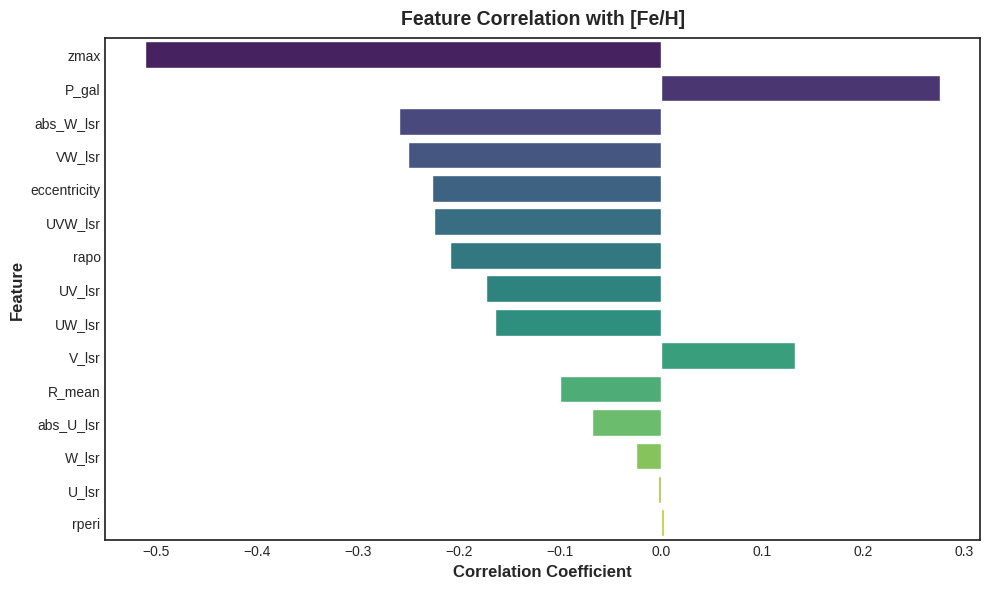

In [221]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.barplot(x=correlations.values, y=correlations.index, palette="viridis")
plt.title('Feature Correlation with [Fe/H]')
plt.xlabel('Correlation Coefficient')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


pandas-profiling (now renamed to ydata-profiling)
✅ What it gives:
Target correlation heatmaps

Distribution plots of features

Missing value analysis

Duplicates detection

Interaction matrices

Report export (HTML, JSON)

In [222]:
from ydata_profiling import ProfileReport
#profile = ProfileReport(X_harps.assign(fe_h=y_harps), title="EDA Report", explorative=True)
#profile.to_file("eda_report.html")  # Opens in your browser


In [223]:
import sweetviz as sv

#report = sv.analyze([harps, "Train"], target_feat="fe_h")
#report.show_html("sweetviz_report.html")


In [224]:
#sv.compare([X_combined_train.assign(fe_h=y_combined_train), "Train"], [harps, "Test"]).show_html("compare.html")


In [225]:
from sklearn.feature_selection import mutual_info_regression
import numpy as np
import pandas as pd

def select_features_by_mi_and_correlation(X, y, corr_thresh=0.9, top_n=None, verbose=True):
    # 1. Compute mutual information
    mi = mutual_info_regression(X, y)
    mi_df = pd.DataFrame({'Feature': X.columns, 'MI': mi}).sort_values(by='MI', ascending=False)

    selected = []
    removed = []
    remaining = list(mi_df['Feature'])

    while remaining:
        # Pick the highest MI feature
        best = remaining.pop(0)
        selected.append(best)

        if verbose:
            print(f"Selected: {best} (MI={mi_df.set_index('Feature').loc[best, 'MI']:.4f})")

        # Remove features highly correlated with 'best'
        to_remove = []
        for feature in remaining:
            corr = np.corrcoef(X[best], X[feature])[0, 1]
            if abs(corr) > corr_thresh:
                to_remove.append(feature)

        for f in to_remove:
            remaining.remove(f)
            removed.append(f)
            if verbose:
                print(f"  Removed due to high correlation with {best}: {f} (|corr|={abs(np.corrcoef(X[best], X[f])[0, 1]):.2f})")

        # Stop if top_n features are selected
        if top_n and len(selected) >= top_n:
            break

    return selected, removed



In [226]:
selected_features_full, removed_features_full = select_features_by_mi_and_correlation(X_full, y_full, corr_thresh=0.999)
print("Selected:", selected_features_full)

Selected: zmax (MI=0.1781)
Selected: rperi (MI=0.1229)
Selected: R_mean (MI=0.0998)
Selected: P_gal (MI=0.0874)
Selected: VW_lsr (MI=0.0870)
Selected: eccentricity (MI=0.0763)
Selected: rapo (MI=0.0755)
Selected: V_lsr (MI=0.0711)
Selected: abs_W_lsr (MI=0.0690)
Selected: W_lsr (MI=0.0616)
Selected: UVW_lsr (MI=0.0524)
Selected: UV_lsr (MI=0.0399)
Selected: UW_lsr (MI=0.0228)
Selected: abs_U_lsr (MI=0.0046)
Selected: U_lsr (MI=0.0023)
Selected: ['zmax', 'rperi', 'R_mean', 'P_gal', 'VW_lsr', 'eccentricity', 'rapo', 'V_lsr', 'abs_W_lsr', 'W_lsr', 'UVW_lsr', 'UV_lsr', 'UW_lsr', 'abs_U_lsr', 'U_lsr']


First 15 of 15 features:
zmax            0.177625
rperi           0.123480
R_mean          0.099446
P_gal           0.086942
VW_lsr          0.086747
eccentricity    0.076940
rapo            0.075821
V_lsr           0.071332
abs_W_lsr       0.068799
W_lsr           0.061768
UVW_lsr         0.052224
UV_lsr          0.040777
UW_lsr          0.023263
abs_U_lsr       0.005556
U_lsr           0.002269
Name: MI Scores, dtype: float64


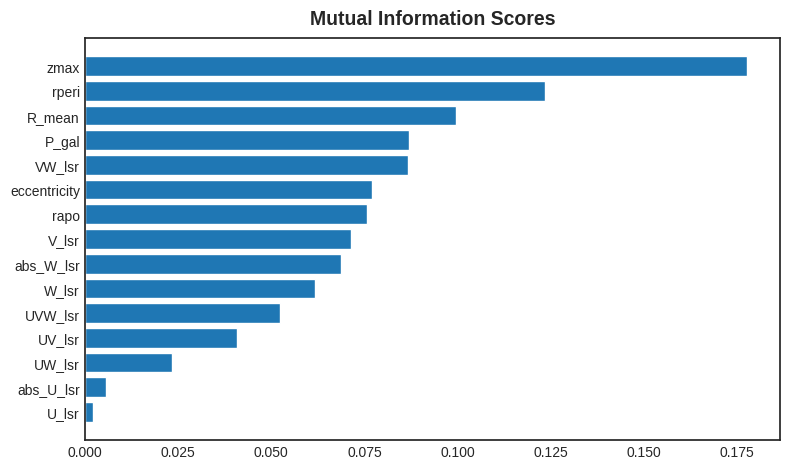

In [227]:
mi_scores_full = make_mi_scores(X_full, y=y_full,  plot = True)

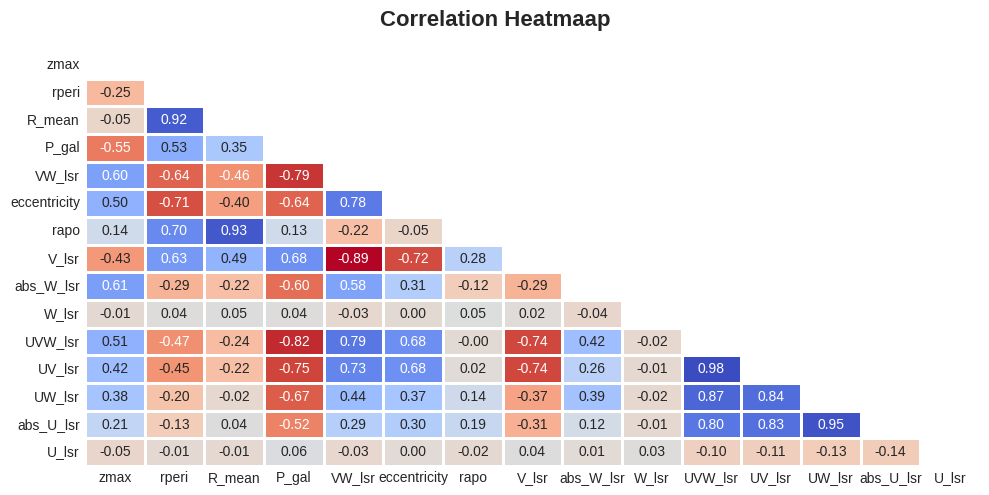

In [228]:
# Displays the correlation hitmap
corr_heatmap_plot(X_full[selected_features_full])

In [229]:
from statsmodels.tools.tools import add_constant
import numpy as np

X_new = X_full[selected_features_full].copy()
X_new = add_constant(X_new)

vif_data = []
for i in range(X_new.shape[1]):
    try:
        vif_value = variance_inflation_factor(X_new.values, i)
    except Exception as e:
        vif_value = np.inf
        print(f"Failed VIF for {X_new.columns[i]}: {e}")
    vif_data.append((X_new.columns[i], vif_value))

vif_df = pd.DataFrame(vif_data, columns=['Variable', 'VIF'])
print(vif_df[vif_df['VIF'] > 0])  # or any threshold you like



        Variable         VIF
0          const   96.506236
1           zmax    2.242218
2          rperi         inf
3         R_mean         inf
4          P_gal    4.589919
5         VW_lsr   41.095439
6   eccentricity   16.919810
7           rapo         inf
8          V_lsr    9.162920
9      abs_W_lsr    9.214642
10         W_lsr    1.007947
11       UVW_lsr  540.360820
12        UV_lsr  319.360770
13        UW_lsr  187.827340
14     abs_U_lsr  105.387240
15         U_lsr    1.030402


/home/vadibekyan/anaconda3/lib/python3.12/site-packages/statsmodels/stats/outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


In [230]:
X_new_low_VIF = X_full[selected_features_full].copy()
X_new_low_VIF = X_new_low_VIF.drop(columns=['UVW_lsr'])
X_new_low_VIF = add_constant(X_new_low_VIF)

vif_data = []
for i in range(X_new_low_VIF.shape[1]):
    try:
        vif_value = variance_inflation_factor(X_new_low_VIF.values, i)
    except Exception as e:
        vif_value = np.inf
        print(f"Failed VIF for {X_new_low_VIF.columns[i]}: {e}")
    vif_data.append((X_new_low_VIF.columns[i], vif_value))

low_vif_df = pd.DataFrame(vif_data, columns=['Variable', 'VIF'])
print(low_vif_df[low_vif_df['VIF'] > 0])  # or any threshold you like

        Variable        VIF
0          const  96.503312
1           zmax   2.234936
2          rperi        inf
3         R_mean        inf
4          P_gal   4.559549
5         VW_lsr  25.397228
6   eccentricity  16.818417
7           rapo        inf
8          V_lsr   8.698905
9      abs_W_lsr   9.101794
10         W_lsr   1.006713
11        UV_lsr  45.686450
12        UW_lsr  64.777224
13     abs_U_lsr  60.978749
14         U_lsr   1.030379


/home/vadibekyan/anaconda3/lib/python3.12/site-packages/statsmodels/stats/outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


In [231]:
best_features = [x for x in selected_features_full if x not in []]

In [232]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold
import numpy as np
import time

def model_test_CV_models(X, y, models, k=5, random_state=42):
    """
    Perform k-fold cross-validation for multiple models.
    Returns mean and std of RMSE, MAE, and R2.
    """
    kf = KFold(n_splits=k, shuffle=True, random_state=random_state)
    results = {}

    for name, model in models.items():
        print(f"Scoring model: {name}")
        start_time = time.time()

        rmse_scores = []
        mae_scores = []
        r2_scores = []

        for train_index, test_index in kf.split(X, y):
            X_train, X_test = X.iloc[train_index], X.iloc[test_index]
            y_train, y_test = y.iloc[train_index], y.iloc[test_index]

            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)

            rmse = np.sqrt(mean_squared_error(y_test, y_pred))
            mae = mean_absolute_error(y_test, y_pred)
            r2 = r2_score(y_test, y_pred)

            rmse_scores.append(rmse)
            mae_scores.append(mae)
            r2_scores.append(r2)

        elapsed_time = time.time() - start_time

        results[name] = {
            'mean_rmse': np.mean(rmse_scores),
            'std_rmse': np.std(rmse_scores),
            'mean_mae': np.mean(mae_scores),
            'mean_r2': np.mean(r2_scores),
            'time_sec': elapsed_time
        }

        print(
            f"{name} → "
            f"RMSE: {results[name]['mean_rmse']:.3f} ± {results[name]['std_rmse']:.3f} | "
            f"MAE: {results[name]['mean_mae']:.3f} | "
            f"R²: {results[name]['mean_r2']:.3f} "
            f"({elapsed_time:.2f}s)\n"
        )

    return results

In [249]:
xgbr = XGBRegressor(random_state=random_state, n_jobs=-1)
lgbr = LGBMRegressor(random_state=random_state, verbosity=-1, n_jobs=-1, objective="huber")

catbr = CatBoostRegressor(
    random_state=random_state,
    verbose=0,            # suppress output
    thread_count=-1
)

from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import QuantileTransformer

qt = QuantileTransformer(
    output_distribution="normal",
    n_quantiles=100,
    random_state=random_state
)

lgbr_qt = TransformedTargetRegressor(
    regressor=lgbr,
    transformer=qt
)

xgbr_qt = TransformedTargetRegressor(
    regressor=xgbr,
    transformer=qt
)

catbr_qt = TransformedTargetRegressor(
    regressor=catbr,
    transformer=qt
)


model_names = {
    'xgbr': xgbr,
    'xgbr_qt': xgbr_qt,
    'lgbr': lgbr,
    'lgbr_qt': lgbr_qt,
    'catbr': catbr,
    'catbr_qt': catbr_qt,
}


In [250]:
baseline_results = model_test_CV_models(X_combined_train[best_features], y_combined_train, model_names, k=5)

for name, score in baseline_results.items():
    print(f"{name:8s} | RMSE: {score['mean_rmse']:.3f} ± {score['std_rmse']:.3f}")


Scoring model: xgbr
xgbr → RMSE: 0.200 ± 0.001 | MAE: 0.157 | R²: 0.383 (1.97s)

Scoring model: xgbr_qt
xgbr_qt → RMSE: 0.201 ± 0.001 | MAE: 0.157 | R²: 0.378 (1.97s)

Scoring model: lgbr
lgbr → RMSE: 0.198 ± 0.001 | MAE: 0.155 | R²: 0.399 (3.02s)

Scoring model: lgbr_qt
lgbr_qt → RMSE: 0.198 ± 0.001 | MAE: 0.155 | R²: 0.397 (4.73s)

Scoring model: catbr
catbr → RMSE: 0.198 ± 0.001 | MAE: 0.155 | R²: 0.397 (34.20s)

Scoring model: catbr_qt
catbr_qt → RMSE: 0.199 ± 0.001 | MAE: 0.155 | R²: 0.393 (33.42s)

xgbr     | RMSE: 0.200 ± 0.001
xgbr_qt  | RMSE: 0.201 ± 0.001
lgbr     | RMSE: 0.198 ± 0.001
lgbr_qt  | RMSE: 0.198 ± 0.001
catbr    | RMSE: 0.198 ± 0.001
catbr_qt | RMSE: 0.199 ± 0.001


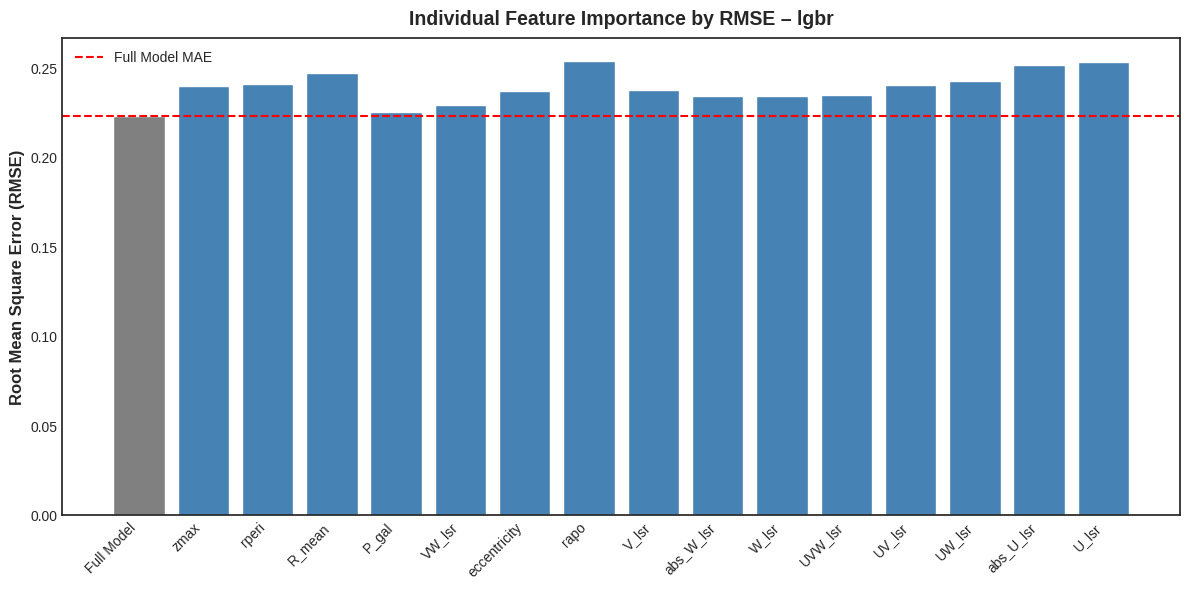

In [235]:
from sklearn.base import clone

def individual_feature_importance(model, model_name, X, y, X_test, y_test):
    """
    Trains a model with each feature individually and compares MAE to full model.
    """
    model_full = clone(model)
    model_full.fit(X, y)

    feature_names = X.columns

    # Full prediction
    y_pred_full = model_full.predict(X_test)
    rmse_full =  np.sqrt(mean_squared_error(y_test, y_pred_full))

    # Individual feature performance
    rmse_individual = []
    for feature in feature_names:
        model_feat = clone(model)
        model_feat.fit(X[[feature]], y)
        y_pred_feat = model_feat.predict(X_test[[feature]])
        rmse_individual.append(np.sqrt(mean_squared_error(y_test, y_pred_feat))) 

    # Plot
    plt.figure(figsize=(12, 6))
    plt.bar(['Full Model'] + list(feature_names), [rmse_full] + rmse_individual, color=['gray'] + ['steelblue']*len(feature_names))
    plt.axhline(y=rmse_full, color='red', linestyle='--', label='Full Model MAE')

    plt.ylabel('Root Mean Square Error (RMSE)')
    plt.title(f'Individual Feature Importance by RMSE – {model_name}')
    plt.xticks(rotation=45, ha='right')
    plt.legend()
    plt.tight_layout()
    plt.show()
    return rmse_individual


# Example for one model and one test set
best_model_name = 'lgbr'
model = model_names[best_model_name]
rmse_individual = individual_feature_importance(model, 'lgbr', X_combined_train[selected_features_full], y_combined_train, X_harps[selected_features_full], y_harps)

Feature importance: ['zmax' 'R_mean' 'eccentricity' 'rapo' 'rperi' 'VW_lsr' 'U_lsr' 'V_lsr'
 'UV_lsr' 'W_lsr' 'UVW_lsr' 'UW_lsr' 'abs_U_lsr' 'abs_W_lsr' 'P_gal']


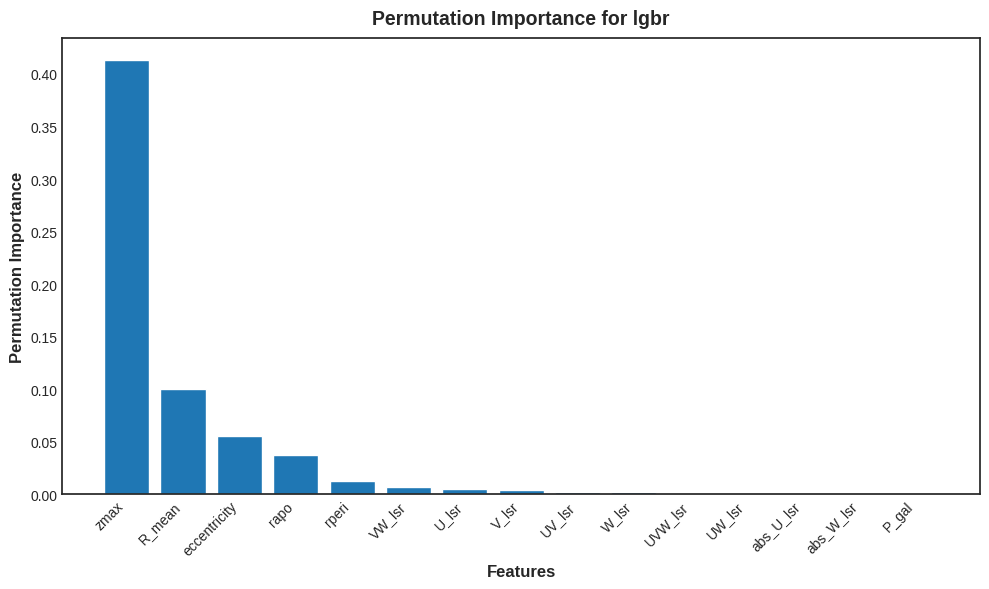

In [236]:
def feat_importance_permut(model, model_name, X, y, n_repeats = 10):
    from sklearn.inspection import permutation_importance

    X_trian, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model.fit(X_trian, y_train)
    

    # Calculate MAE on the original test set
    y_pred = model.predict(X_test)
    mae_original =  np.sqrt(mean_squared_error(y_test, y_pred))

    # Use permutation importance to obtain feature importances
    result = permutation_importance(model, X_test, y_test, n_repeats=n_repeats, random_state=42)

    # Get feature importances and indices
    feature_importances = result.importances_mean
    sorted_indices = feature_importances.argsort()[::-1]

    print (f'Feature importance: {X.columns[sorted_indices].values}')

    # Plot the feature importances
    plt.figure(figsize=(10, 6))
    plt.bar(range(len(sorted_indices)), feature_importances[sorted_indices], tick_label=X.columns[sorted_indices])
    plt.xlabel('Features')
    plt.ylabel('Permutation Importance')
    plt.title(f'Permutation Importance for {model_name}')
    plt.xticks(rotation=45, ha='right')
    plt.show()

feat_importance_permut(model, 'lgbr', X_combined_train[best_features], y_combined_train, n_repeats = 10)

In [237]:
def ols(x, y):
    x_with_const = sm.add_constant(x)
    model = sm.OLS(y, x_with_const)
    results = model.fit()
    coeff1_ols, coeff2_ols = results.params[0], results.params[1]
    p_values = results.pvalues
    return coeff1_ols, coeff2_ols, p_values

MAE = 0.15


/tmp/ipykernel_14274/4033565634.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coeff1_ols, coeff2_ols = results.params[0], results.params[1]
/tmp/ipykernel_14274/4033565634.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coeff1_ols, coeff2_ols = results.params[0], results.params[1]
/tmp/ipykernel_14274/3343164355.py:35: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ax_i.set_title(f"{p_value[1]:.2f}")
/tmp/ipykernel_14274/40

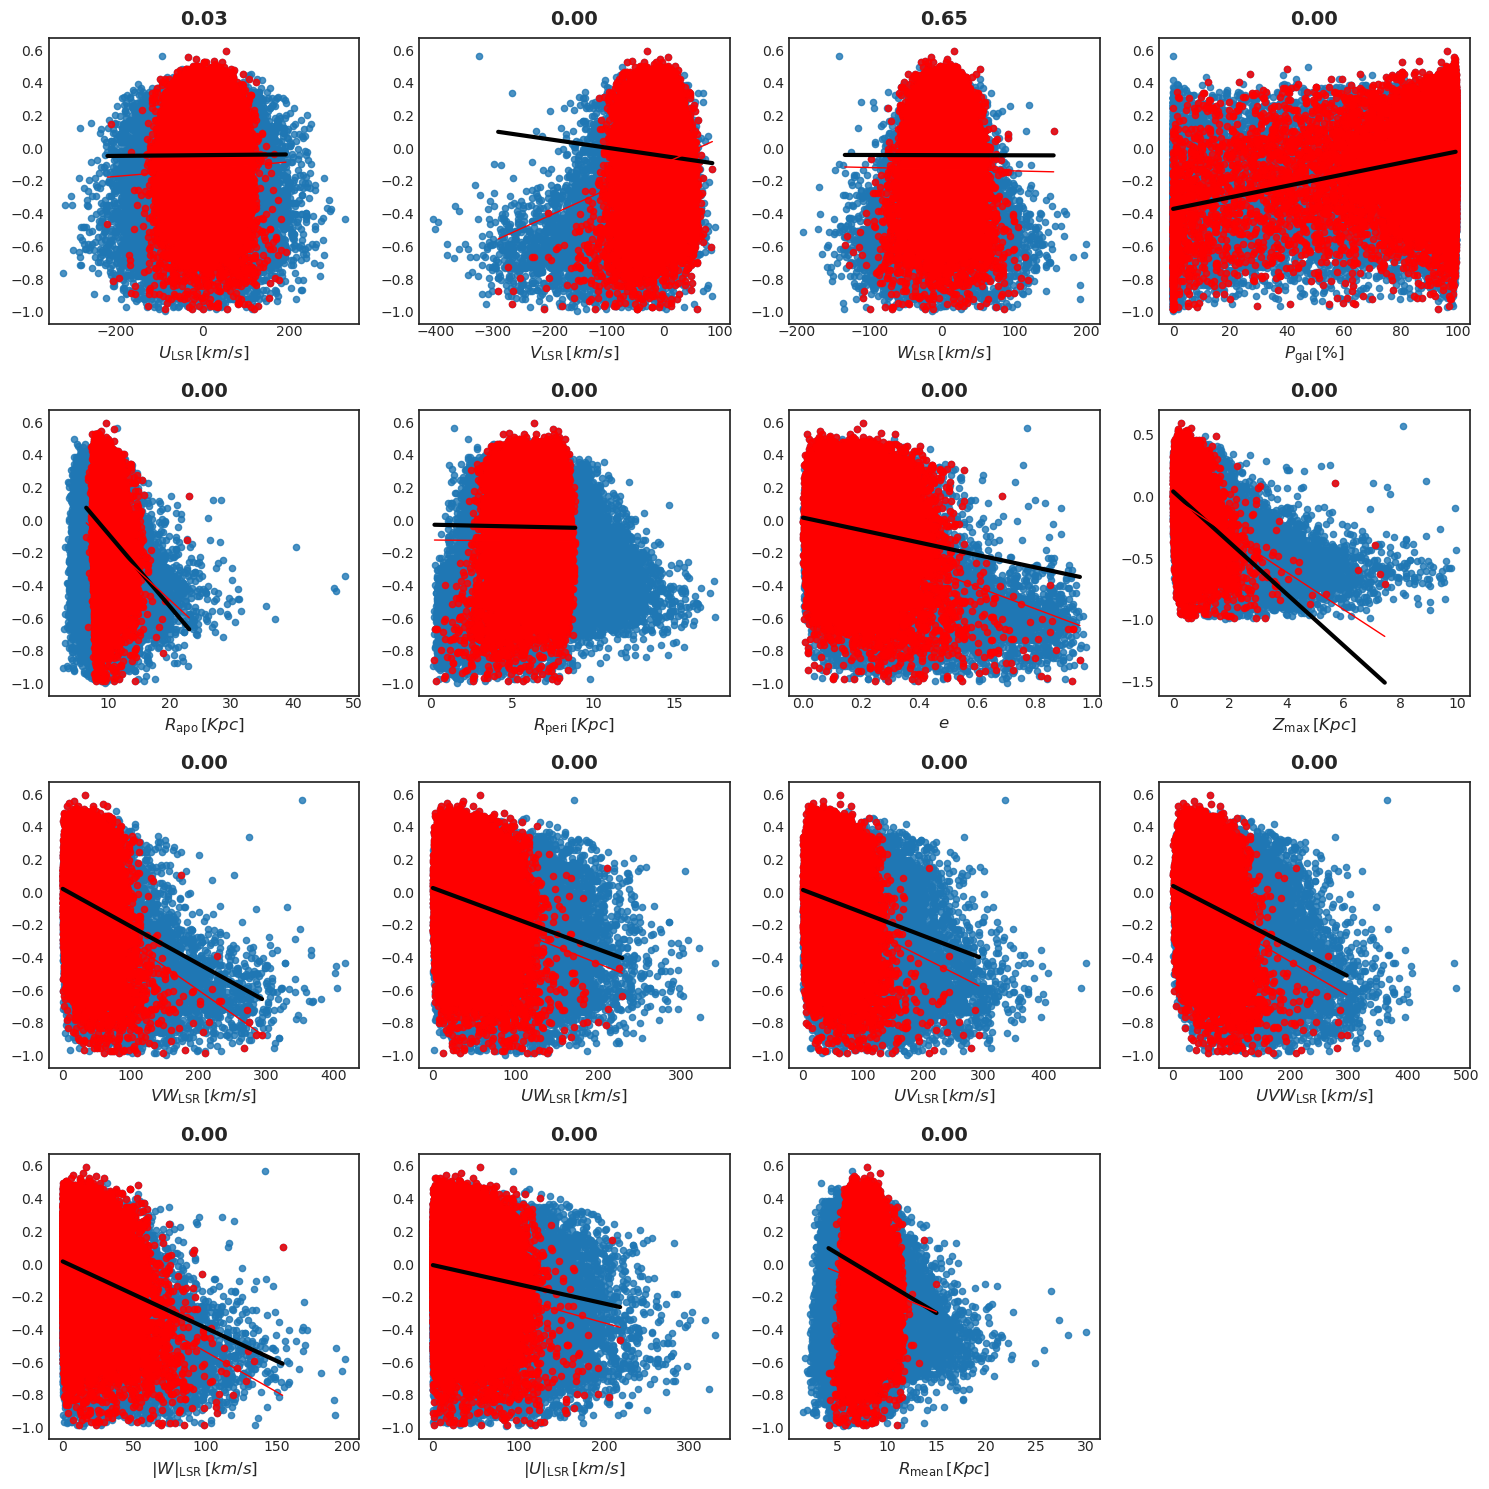

In [238]:

def dependence_on_feature_plot(model, X, y, X_test, y_test):
    model.fit(X, y)
    y_pred = model.predict(X_test)
    print(f"MAE = {mean_absolute_error(y_test, y_pred):.2f}")

    # styling
    import seaborn as sns
    sns.set_style("white")
    fig, ax = plt.subplots(4, 4, figsize=(15, 15))
    axes = ax.flatten()

    # iterate features (cap at number of axes)
    for i, feature in enumerate(X.columns[:len(axes)]):
        # simple OLS on test and train
        coeff1_ols, coeff2_ols, p_value = ols(X_test[feature], y_pred)
        coeff1_tr, coeff2_tr, p_value_tr = ols(X[feature], y)

        # line range from test feature range
        x_min = np.nanmin(X_test[feature])
        x_max = np.nanmax(X_test[feature])
        x_line = np.linspace(x_min, x_max, 200)

        y_line = coeff1_ols + coeff2_ols * x_line
        y_line_tr = coeff1_tr + coeff2_tr * x_line

        ax_i = axes[i]
        ax_i.scatter(X[feature], y, s=20, alpha=0.8)
        ax_i.scatter(X_test[feature], y_test, s=20, color="red", alpha=0.8)
        ax_i.plot(x_line, y_line, lw=3, color="black")
        ax_i.plot(x_line, y_line_tr, lw=1, color="red", label="Train")

        # pretty xlabel
        ax_i.set_xlabel(PRETTY_LABELS.get(feature, feature), fontsize=12)
        # show p-value for test fit in title
        ax_i.set_title(f"{p_value[1]:.2f}")

        ax_i.tick_params(axis="x", which="major", labelsize=10, pad=0)
        ax_i.tick_params(axis="y", which="major", labelsize=10)

    # turn off any unused subplots
    for j in range(len(X.columns), len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

dependence_on_feature_plot(model, X_combined_train, y_combined_train, X_galah, y_galah)

/tmp/ipykernel_14274/4033565634.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coeff1_ols, coeff2_ols = results.params[0], results.params[1]
/tmp/ipykernel_14274/4004556215.py:53: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  p_slope = float(pvals[1])
/tmp/ipykernel_14274/4033565634.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coeff1_ols, coeff2_ols = results.params[0], results.params[1]
/tmp/ipykernel_14274/4004556215.p

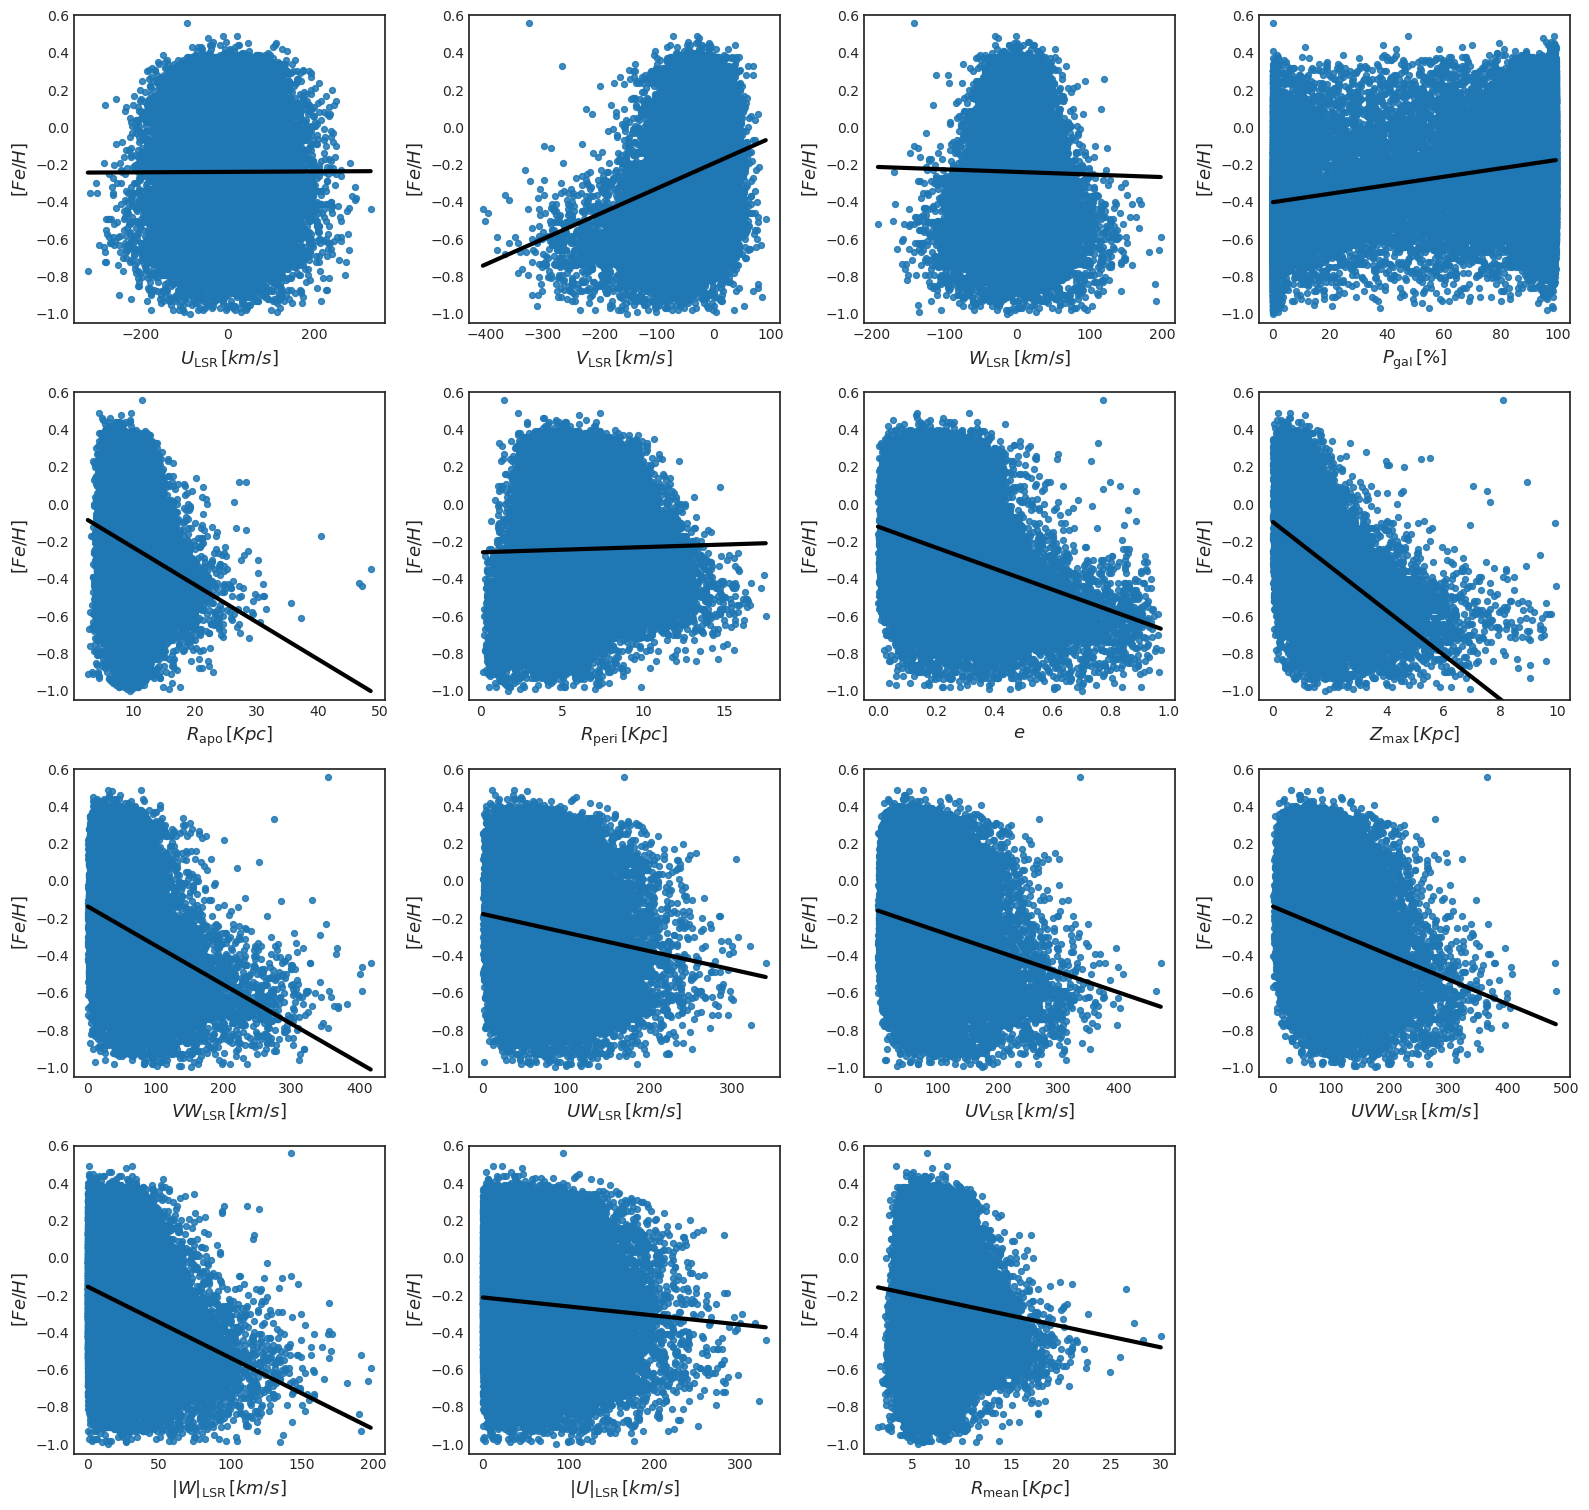

In [239]:

def dependence_on_feature_plot_df(X, y, *, ncols=4, add_fit=True, ols_func=None):
    """
    Plot y as a function of each feature in X (single dataset).
    
    Parameters
    ----------
    X : pandas.DataFrame
        Features (columns will be iterated).
    y : array-like or pandas.Series
        Target values aligned with X.
    ncols : int, optional
        Number of columns in the subplot grid (default 4).
    add_fit : bool, optional
        If True, adds a best-fit line (OLS).
    ols_func : callable, optional
        Custom OLS function with signature (x, y) -> (intercept, slope, pvals_array_or_scalar).
        If None, uses np.polyfit for slope/intercept and omits p-values.
    """
    import numpy as np
    import matplotlib.pyplot as plt
    import seaborn as sns
    import math
    import pandas as pd

    # Ensure alignment & drop rows with NaNs in y or any feature being plotted
    data = pd.concat([X, pd.Series(y, index=X.index, name="_y")], axis=1)

    features = list(X.columns)
    n = len(features)
    nrows = math.ceil(n / ncols)

    sns.set_style("white")
    fig, ax = plt.subplots(nrows, ncols, figsize=(4*ncols, 3.8*nrows))
    axes = np.atleast_1d(ax).ravel()

    for i, feat in enumerate(features):
        ax_i = axes[i]
        df_i = data[[feat, "_y"]].dropna()

        x = df_i[feat].values
        yy = df_i["_y"].values

        # scatter
        ax_i.scatter(x, yy, s=18, alpha=0.85)

        title_txt = ""
        if add_fit and len(df_i) >= 2:
            # Fit line using provided OLS or fallback to np.polyfit
            if ols_func is not None:
                c0, c1, pvals = ols_func(df_i[feat], df_i["_y"])
                # p-value: if array-like, assume slope at index 1
                try:
                    p_slope = float(pvals[1])
                except Exception:
                    p_slope = float(pvals)
                title_txt = f"$p_{{\\mathrm{{slope}}}}$ = {p_slope:.2e}"
            else:
                # Fallback: least squares (no p-value)
                c1, c0 = np.polyfit(x, yy, 1)
                title_txt = r"OLS fit (no $p$)"

            # line
            x_line = np.linspace(np.nanmin(x), np.nanmax(x), 200)
            y_line = c0 + c1 * x_line
            ax_i.plot(x_line, y_line, lw=3, color="black")

        ax_i.set_xlabel(PRETTY_LABELS.get(feat, feat), fontsize=13)
        ax_i.set_ylim(-1.05, 0.6)
        ax_i.set_ylabel(r"$[Fe/H]$", fontsize=13)
        #if title_txt:
        #    ax_i.set_title(title_txt, fontsize=11)
        ax_i.tick_params(axis="both", labelsize=10)

    # remove unused axes
    for j in range(n, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.savefig('dependence_on_feature_plot_df.png', dpi=300)
    plt.show()



# If you have your existing `ols` function:
dependence_on_feature_plot_df(X_apogee, y_apogee, ncols=4, add_fit=True, ols_func=ols)

# Or without p-values (fallback fit):
# dependence_on_feature_plot_df(X_one, y_one, ncols=4, add_fit=True)


In [240]:
import matplotlib.pyplot as plt
import numpy as np

def plot_residuals_vs_true(y_true, y_pred, model_name='Model', sample_name='Test Set'):
    """
    Plot residuals (y_true - y_pred) vs y_true, and residuals from predicting the mean.

    Parameters:
        y_true: Ground truth target values.
        y_pred: Model predictions.
        model_name: Name of the model for labeling.
        sample_name: Name of the dataset (e.g., 'Apogee' or 'HARPS').
    """
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_mean = np.full_like(y_true, y_true.mean())

    residuals_model = y_true - y_pred
    residuals_mean = y_true - y_mean

    plt.figure(figsize=(10, 6))
    plt.scatter(y_true, residuals_model, alpha=0.6, label=f'{model_name}', s=20)
    plt.scatter(y_true, residuals_mean, alpha=0.4, label='Mean predictor', s=20, marker='x')

    plt.axhline(0, color='gray', linestyle='--')
    plt.xlabel('True Value (y)')
    plt.ylabel('Residual (y_true - y_pred)')
    plt.title(f'Residuals vs True Values ({sample_name})')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


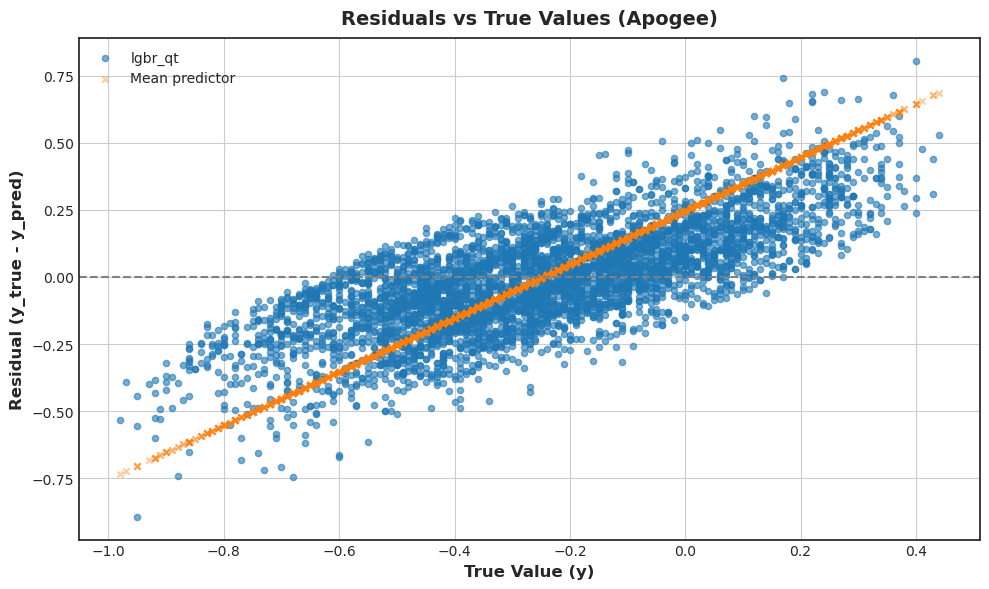

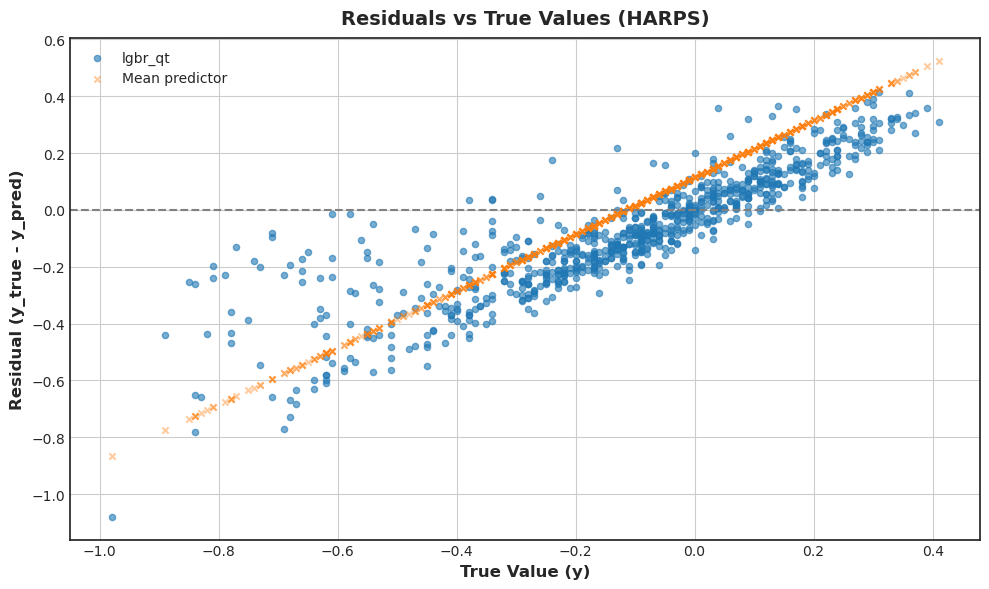

In [251]:
# Example for one model and one test set
best_model_name = 'lgbr_qt'
model = model_names[best_model_name]
model.fit(X_combined_train, y_combined_train)

y_pred_apogee = model.predict(X_apogee_test)
plot_residuals_vs_true(y_apogee_test, y_pred_apogee, model_name=best_model_name, sample_name='Apogee')

y_pred_harps = model.predict(X_harps)
plot_residuals_vs_true(y_harps, y_pred_harps, model_name=best_model_name, sample_name='HARPS')

#y_pred_galah = model.predict(X_galah_test)
#plot_residuals_vs_true(y_galah_test, y_pred_galah, model_name=best_model_name, sample_name='GALAH')


In [242]:
apogee_final_for_feh = apogee[[*best_features,'fe_h']]
apogee_final_for_feh.to_csv('apogee_final_for_feh.csv', index=False)

galah_final_for_feh = galah[[*best_features,'fe_h']]
galah_final_for_feh.to_csv('galah_final_for_feh.csv', index=False)

harps_final_for_feh = harps[[*best_features,'fe_h']]
harps_final_for_feh.to_csv('harps_final_for_feh.csv', index=False)

In [243]:
y_apogee.describe()

count    41153.000000
mean        -0.238736
std          0.259871
min         -1.000000
25%         -0.430000
50%         -0.250000
75%         -0.050000
max          0.560000
Name: fe_h, dtype: float64